<!-- Everything Is an Object
In Python, there are no primitives in the C sense.

Every value - integer, float, boolean, string, None - is a full object. -->

# Everything Is an Object
## In Python, there are no primitives in the C sense.
## Every value - integer, float, boolean, string, None - is a full object.

In [2]:
import sys
x = 42
print(type(x))
print(id(x))
print(sys.getsizeof(x)) #--> bytes

<class 'int'>
140719778687384
28


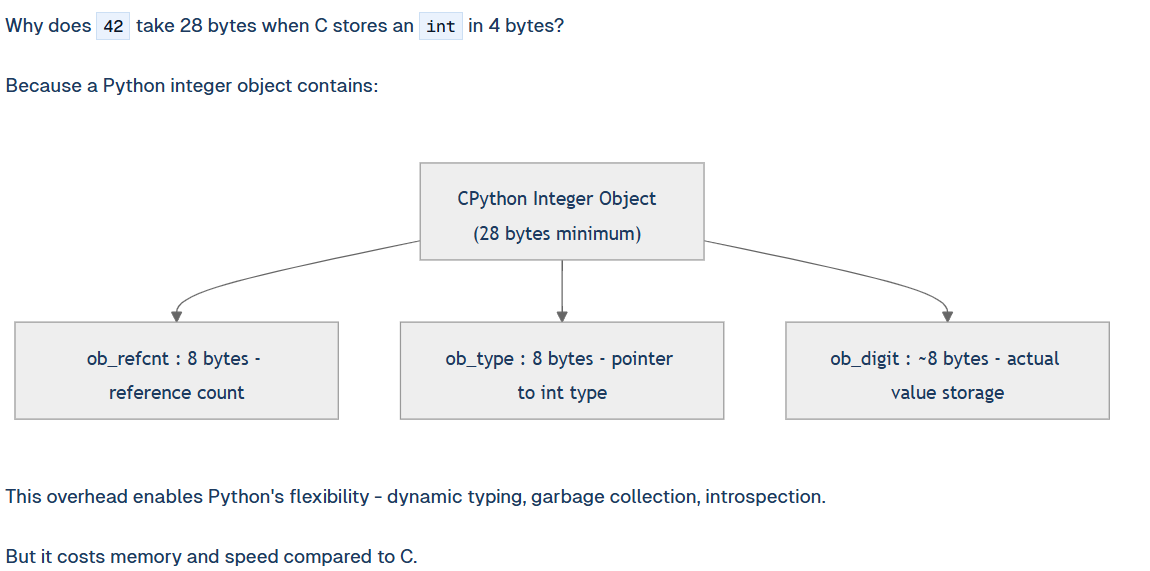

## Integer Interning: The Trap That Fools Experts
### CPython caches integers from -5 to 256 for performance.

In [6]:
a = 100
b = 100
print(a is b)   # True  - same cached object

a = 1000
b = 1000
print(a is b)   # False - different objects (outside cache range)

a = 5000
b = a
print(a is b)   # False - different objects (outside cache range)

True
False
True


In [3]:
# Correct: checking for None
if result is None:
    handle_missing()

# Correct: checking for True/False singletons
if flag is True:
    do_something()

# Correct: checking class identity
if type(x) is int:
    process_integer(x)

NameError: name 'result' is not defined

# How Python Stores Variables — Stack vs Heap (In-Depth Notes)

---

## 1. Why Learn This?

Knowing how memory works explains many "strange" Python behaviours:
- Why changing one list changes another
- Why `a is b` is sometimes `True` and sometimes `False`
- Why memory gets freed automatically
- Why functions can modify a list you pass in, but not an integer

---

## 2. Computer Memory Basics (RAM)

When a program runs, the operating system gives it a region of RAM. That region is organised into parts. The two most important are:

| | **Stack** | **Heap** |
|---|---|---|
| What it holds | Function calls (frames), local names / references | The actual data (objects) |
| Size | Small, fixed limit | Large, grows as needed |
| Speed | Very fast | Slower (needs management) |
| Order | LIFO: Last In, First Out | Any order |
| Lifetime | Freed automatically when the function returns | Lives as long as something refers to it |
| Managed by | Function call / return | A memory manager (in Python: reference counting + garbage collector) |

```
+---------------------------+
|        STACK              |  ← function frames (grow / shrink with calls)
|   frame: greet()          |
|   frame: main / module    |
+---------------------------+
|           ↓  ↑            |
|      (free space)         |
+---------------------------+
|        HEAP               |  ← all objects: 10, "hello", [1,2,3], {...}
+---------------------------+
```

---

## 3. The Golden Rule in Python

> **Objects live on the heap. Variable names are just references that point to those objects.**

In languages like **C**, a variable can *be* a box on the stack holding the value directly:

```c
int x = 10;   // the value 10 sits inside x's stack slot
```

In **Python**, *everything is an object*, even `10`, `True` and `None`. All objects are created in Python's **private heap**. A variable only holds a **reference** (in CPython, effectively a memory address) to the object.

```python
x = 10
```

```
   STACK / NAMESPACE              HEAP
  +---------+               +------------------+
  |   x  ●──┼──────────────►|  int object: 10  |
  +---------+               |  type: int       |
                            |  refcount: ...   |
                            +------------------+
```

Every object on the heap carries at least:
- its **type** (int, str, list...)
- its **value**
- a **reference count** (how many references point to it)

---

## 4. Where Do the *Names* Live? (Namespaces & Frames)

Names are stored in **namespaces**:

| Namespace | Where it's stored | See it with |
|-----------|------------------|------------|
| **Global** (module / notebook level) | a dictionary | `globals()` |
| **Local** (inside a function) | the function's **frame** on the call stack | `locals()` |
| **Built-in** | the `builtins` module | `dir(__builtins__)` |

```python
x = 10
print(globals()['x'])   # 10 → the name 'x' is a key in the globals dict
```

### The Call Stack and Frames
Each time a function is **called**, Python creates a **frame** for it. The frame holds:
- references for that function's **local variables**
- arguments passed in
- where to return to afterwards

Frames are **pushed** onto the call stack when a function is called and **popped** off when it returns (LIFO).

```python
def square(n):
    result = n * n
    return result

def main():
    a = 4
    b = square(a)
    print(b)

main()
```

While `square` is running:

```
        CALL STACK (frames)                    HEAP
  +-----------------------------+
  | square()                    |
  |   n      ●──────────────────┼──────►  [ int 4  ]  ◄──┐
  |   result ●──────────────────┼──────►  [ int 16 ]     │
  +-----------------------------+                        │
  | main()                      |                        │
  |   a      ●──────────────────┼────────────────────────┘
  |   b      (not assigned yet) |
  +-----------------------------+
  | <module> (global)           |
  +-----------------------------+
```

After `square` returns:
- Its frame is **popped**. The names `n` and `result` disappear.
- The object `16` **survives**, because `b` now refers to it.
- The object `4` survives because `a` still refers to it.

> **Note (CPython detail):** Python's call stack is not the same as the C/hardware stack. Frames are managed by the interpreter itself. The *idea* is the same, though: frames hold references and the objects live on the heap.

---

## 5. Step-by-Step Examples

### Example 1: Two names, one object
```python
a = 500
b = a
```
```
  a ──┐
      ├──►  [ int 500 ]   (refcount includes a and b)
  b ──┘
```
```python
print(a is b)        # True
print(id(a) == id(b)) # True
```
`b = a` does **not** copy the object. It copies the **reference**.

### Example 2: Re-assigning an immutable value
```python
a = 500
b = a
a = a + 1
```
```
  a ──►  [ int 501 ]   ← new object created
  b ──►  [ int 500 ]   ← unchanged
```
Integers are **immutable**, so `a + 1` builds a **new** object on the heap, and `a` is pointed to it.

### Example 3: Mutating a mutable object
```python
x = [1, 2, 3]
y = x
y.append(4)
print(x)   # [1, 2, 3, 4]
```
```
  x ──┐
      ├──►  [ list: ●  ●  ●  ● ]
  y ──┘            │  │  │  │
                   ▼  ▼  ▼  ▼
                   1  2  3  4   (each is its own int object on the heap)
```
There is only **one** list on the heap. Both names see the change.

> A list does not hold the numbers directly. It holds **references** to int objects, which are also on the heap.

### Example 4: A real copy
```python
x = [1, 2, 3]
y = x.copy()
```
```
  x ──►  [ list A ]──┐
                     ├──►  1, 2, 3   (the same int objects are shared)
  y ──►  [ list B ]──┘
```
A **shallow copy** makes a new list but shares the inner objects. That is fine for immutable items. For nested lists, use `copy.deepcopy()`.

---

## 6. Functions: "Pass by Object Reference"

Python passes **references** to objects into functions (sometimes called *call by sharing*).

### Immutable argument: the caller is not affected
```python
def add_one(n):
    n = n + 1        # n now points to a NEW object
    return n

num = 5
add_one(num)
print(num)   # 5
```
```
  main:     num ──►  [ 5 ]
  add_one:  n   ──►  [ 5 ]  → after n = n + 1 →  n ──► [ 6 ]
```

### Mutable argument: the caller *is* affected
```python
def add_item(lst):
    lst.append(99)   # modifies the SAME list object

items = [1, 2]
add_item(items)
print(items)   # [1, 2, 99]
```

### Re-binding inside a function does not affect the caller
```python
def replace(lst):
    lst = [0, 0]     # lst now points to a new list; the original is untouched

items = [1, 2]
replace(items)
print(items)   # [1, 2]
```

> **Rule:** *Mutating* an object is visible everywhere. *Re-binding* a name is local.

---

## 7. How Python Frees Memory

You never call `free()` in Python. The memory manager does it.

### a) Reference Counting (main mechanism)
Every object counts how many references point to it. When the count reaches **0**, the object is destroyed immediately.

```python
import sys

a = [1, 2, 3]
print(sys.getrefcount(a))   # e.g. 2 (one extra temporary ref from the call itself)

b = a
print(sys.getrefcount(a))   # goes up by 1

del b
print(sys.getrefcount(a))   # goes back down
```

The count goes **up** when you:
- assign it to a name (`b = a`)
- put it in a container (`lst.append(a)`)
- pass it to a function

The count goes **down** when you:
- `del` a name
- re-assign the name to something else
- a function returns (its local names disappear)
- remove it from a container

### b) Garbage Collector (for reference cycles)
Reference counting can't free **cycles** (objects that refer to each other):

```python
a = []
b = []
a.append(b)
b.append(a)
del a, b    # each list still refers to the other → count never reaches 0
```
Python's **cyclic garbage collector** (the `gc` module) periodically finds and frees these.

```python
import gc
gc.collect()   # force a collection (returns the number of objects collected)
```

---

## 8. Memory Optimisations in CPython

### Small Integer Caching
CPython pre-creates integers from **-5 to 256** and reuses them.

```python
a = 100
b = 100
print(a is b)   # True  → same cached object

x = 1000
y = 1000
print(x is y)   # May be True or False! Implementation detail, don't rely on it
```

### String Interning
Short, identifier-like strings are often reused (**interned**).

```python
s1 = "hello"
s2 = "hello"
print(s1 is s2)   # usually True

import sys
s3 = sys.intern("hello world!")
s4 = sys.intern("hello world!")
print(s3 is s4)   # True (forced interning)
```

> ⚠️ **Always use `==` to compare values.** Use `is` only for `None` (and for checking identity on purpose). Caching behaviour can differ between Python versions and between Jupyter and scripts.

### pymalloc
For small objects, CPython uses its own fast allocator (**pymalloc**). It grabs big chunks from the OS (**arenas**), splits them into **pools**, and splits those into fixed-size **blocks**. That's why creating many small objects is fast. It also means freed memory isn't always returned to the OS right away.

---

## 9. Measuring Memory

```python
import sys

print(sys.getsizeof(10))          # bytes used by the int object
print(sys.getsizeof("hello"))     # string object
print(sys.getsizeof([]))          # empty list
print(sys.getsizeof([1, 2, 3]))   # list object only, NOT the ints inside it
```

> `sys.getsizeof()` measures only the object itself, not the objects it references. Exact numbers depend on your Python version and whether it's 32- or 64-bit.

```python
x = 42
print(id(x))        # identity (in CPython, the memory address)
print(hex(id(x)))   # address shown in hex
```

---

## 10. Python vs C: Side-by-Side

| Concept | C | Python |
|--------|---|--------|
| `x = 10` | value stored in x's own stack slot | `x` refers to an int object on the heap |
| `y = x` | copies the **value** | copies the **reference** |
| Who frees heap memory? | You (`malloc` / `free`) | Automatic (refcount + GC) |
| Variable has a type? | Yes, fixed | No. The **object** has the type |
| Risk of dangling pointers / leaks | High | Very low |

---

## 11. Visual Summary

```
   NAMES (namespaces / frames)              OBJECTS (private heap)
  ─────────────────────────────           ───────────────────────────
   globals():                              
     a ─────────────────────────────────►  int 500
     b ─────────────────────────────────►  (same int 500)
     nums ──────────────────────────────►  list ──► 1, 2, 3
     name ──────────────────────────────►  str "Ravi"

   frame of square():                      
     n ─────────────────────────────────►  int 4
     result ────────────────────────────►  int 16
     (frame popped on return → names gone; objects stay if still referenced)
```

---

## 12. Key Takeaways

1. **All Python objects live on the heap** (Python's private heap).
2. **Variables are names (references)**, stored in namespaces: a dict for globals, and function frames for locals.
3. The **call stack** holds frames. A frame is created on a call and removed on return.
4. **Assignment never copies an object.** It copies a reference.
5. **Immutable** objects (int, str, tuple) can't change, so "changing" one creates a new object.
6. **Mutable** objects (list, dict, set) change in place, and every name pointing to them sees it.
7. Memory is freed by **reference counting**, plus the **garbage collector** for cycles.
8. CPython caches **small ints (-5 to 256)** and interns some **strings**. Compare values with `==`, not `is`.

---

## 13. Practice Exercises

1. Run this and explain the output using a heap diagram:
   ```python
   a = [10, 20]
   b = a
   a = a + [30]
   print(a, b)
   ```
   *(Hint: `a + [30]` creates a new list. Compare that with `a += [30]` and try it!)*

2. Predict, then run:
   ```python
   def change(x, y):
       x = 100
       y.append(100)

   n = 1
   lst = [1]
   change(n, lst)
   print(n, lst)
   ```

3. Use `id()` to show that `b = a` makes both names point to the same object.

4. Check `sys.getrefcount()` for a list before and after adding it to another list.

5. Test `a is b` for `a = b = 256`, and then for `a = 257; b = 257` written on separate lines. Note what you see (results can vary).

6. Draw the stack and heap diagram for:
   ```python
   def make_list():
       data = [1, 2, 3]
       return data

   result = make_list()
   ```
   What happens to the name `data` after the function returns? What happens to the list?

In [8]:
a = [10, 20]
b = a
a = a + [30]
print(a, b)

[10, 20, 30] [10, 20]


In [11]:
a = [10, 20]
b = a
a+=[30]
print(a, b)

[10, 20, 30] [10, 20, 30]


In [16]:
a = [10, 20,40]
b = a
print(sys.getrefcount(a))
a = a + [30]
print(a, b)
print(sys.getrefcount(a))
c = [10, 20,40]
d = c
print(sys.getrefcount(c))
c+=[30]
print(c, d)
print(sys.getrefcount(c)) #------>extra temporary refernce to get reference count by refcount()

3
[10, 20, 40, 30] [10, 20, 40]
2
3
[10, 20, 40, 30] [10, 20, 40, 30]
3


In [17]:

   def change(x, y):
       x = 100
       y.append(100)

   n = 1
   lst = [1]
   change(n, lst)
   print(n, lst)
 

1 [1, 100]
